In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
df = pd.read_csv('train.csv')

## Exploratieve Data Analyse

### 1.1 Onderzoeksvraag

**Welk Machine Learning model voorspelt het risico op een herseninfarct het best op basis van de beschikbare patiëntgegevens, gemeten met de F1-score?**

### 1.2 Kolombeschrijving

De dataset bevat gegevens van patiënten. Het doel is te voorspellen of een patiënt een beroerte (*stroke*) heeft gehad. De originele omschrijvingen zijn in het Engels; hieronder staat per kolom een uitleg in het Nederlands.

#### 1.2.1 Identificatie en doelvariabele

| Kolom | Type | Uitleg |
|-------|------|--------|
| `id` | Identificatie | Unieke identificatiecode van de patiënt. Dit is geen inhoudelijk kenmerk en heeft dus geen voorspellende waarde. |
| `stroke` | Binair (*target*) | De doelvariabele die we willen voorspellen: 1 = de patiënt heeft een beroerte gehad, 0 = geen beroerte. |

#### 1.2.2 Numerieke kolommen

| Kolom | Type | Uitleg |
|-------|------|--------|
| `age` | Numeriek | Leeftijd van de patiënt in jaren. |
| `avg_glucose_level` | Numeriek | Gemiddeld bloedglucosegehalte van de patiënt. |
| `bmi` | Numeriek | Body mass index: de verhouding tussen gewicht en lengte. |

#### 1.2.3 Binaire kolommen

| Kolom | Type | Uitleg |
|-------|------|--------|
| `hypertension` | Binair | Heeft de patiënt hoge bloeddruk? 0 = nee, 1 = ja. |
| `heart_disease` | Binair | Heeft de patiënt een hartziekte? 0 = nee, 1 = ja. |

#### 1.2.4 Dummy kolommen 

De categorische kolommen zijn al omgezet naar dummy kolommen. Elke categorie heeft een eigen kolom met de waarde 1 (de patiënt hoort bij deze categorie) of 0 (niet). Zo kunnen ML modellen met deze gegevens rekenen.

| Kolom | Uitleg |
|-------|--------|
| `gender_Female` | Patiënt is vrouw. |
| `gender_Male` | Patiënt is man. |
| `gender_Other` | Geslacht is "anders". |
| `ever_married_No` | Patiënt is nooit getrouwd geweest. |
| `ever_married_Yes` | Patiënt is ooit getrouwd geweest. |
| `work_type_Govt_job` | Patiënt heeft een overheidsbaan. |
| `work_type_Never_worked` | Patiënt heeft nooit gewerkt. |
| `work_type_Private` | Patiënt werkt in de particuliere sector. |
| `work_type_Self-employed` | Patiënt is zelfstandige. |
| `work_type_children` | Patiënt is een kind (werkt nog niet). |
| `Residence_type_Rural` | Patiënt woont op het platteland. |
| `Residence_type_Urban` | Patiënt woont in de stad. |
| `smoking_status_formerly smoked` | Patiënt heeft vroeger gerookt. |
| `smoking_status_never smoked` | Patiënt heeft nooit gerookt. |
| `smoking_status_smokes` | Patiënt rookt op dit moment. |

De categorie `Unknown` (rookgedrag onbekend) heeft geen eigen dummy-kolom. Een patiënt met overal `0` bij de drie `smoking_status_`-kolommen heeft dus een onbekende rookstatus.

### 1.3 Geschiktheid voor Machine Learning met Scikit-Learn

**Dataset:** `train.csv`  
**Observaties:** 33.550 patiënten  
**Doelvariabele:** `stroke` (0 = geen herseninfarct, 1 = herseninfarct)


De dataset voldoet grotendeels al aan de technische minimumeisen voor Scikit-Learn:

| Controle | Resultaat | Beoordeling / actie |
|---|---:|---|
| Aantal observaties | 33.550 | Voldoende voor classificatie. |
| Aantal kolommen | 22 | Hiervan zijn 20 bruikbare kandidaat-features na het verwijderen van `id` en `stroke`. |
| Ontbrekende waarden | 0 | Geen imputatie nodig. |
| Exact dubbele rijen | 0 | Geen actie nodig. |
| Unieke `id`-waarden | 33.550 | `id` is een identifier en moet uit de features worden verwijderd. |
| Oneindige numerieke waarden | 0 | Geen actie nodig. |
| Doelvariabele | Binair, waarden 0 en 1 | Geschikt voor supervised binary classification. |
| Categorische variabelen | Al als dummyvariabelen aanwezig | Technisch direct bruikbaar na conversie van `bool` naar 0/1 indien een model dit vereist. |


#### 1.3.1 Noodzakelijke aanpassingen

1. **`id` wordt uit de featurematrix verwijderd.** Deze variabele is uitsluitend een patiëntidentificatie en bevat geen inhoudelijke medische informatie. Wanneer `id` als feature wordt meegenomen, kan het model schijnpatronen leren die niet generaliseren naar nieuwe patiënten.

2. **`stroke` wordt uitsluitend als targetvariabele gebruikt en niet als feature opgenomen.** Hierdoor wordt voorkomen dat het model de uitkomstvariabele al als invoer ontvangt.

3. **Boolean variabelen worden, wanneer dit vereist is door het model of de preprocessing, omgezet naar gehele 0/1-waarden.** Hierdoor kunnen modellen en preprocessingsstappen die geen booleaanse waarden verwerken, deze variabelen correct gebruiken.

4. **De train-test-split wordt gestratificeerd uitgevoerd**, met `train_test_split(..., stratify=y)`. Omdat de positieve klasse zeer zeldzaam is, blijft de klasseverdeling hierdoor in zowel de train- als testset behouden.

5. **Cross-validatie wordt uitgevoerd met `StratifiedKFold`.** Hierdoor blijft de verhouding tussen patiënten met en zonder stroke in iedere fold zoveel mogelijk gelijk aan die in de volledige dataset.

6. **Scaling wordt voor KNN, Logistic Regression en SVM opgenomen in een `Pipeline`.** De scaler wordt hierdoor uitsluitend op de trainingsdata gefit. Wanneer schaling vóór de train-test-split wordt uitgevoerd, ontstaat datalekken doordat informatie uit de testset in het trainingsproces terechtkomt.

7. **De F1-score wordt als primaire evaluatiemaatstaf gebruikt in plaats van accuracy.** Door de sterke klasse-onbalans geeft accuracy geen betrouwbaar beeld van de prestaties op de zeldzame positieve klasse. De klasse-onbalans wordt daarnaast verwerkt met bijvoorbeeld `class_weight='balanced'` en/of resampling. Resampling wordt uitsluitend op de trainingsdata of binnen iedere cross-validatiefold toegepast.




### 2. Datatypes en basisstatistieken



Voor numerieke kolommen zijn minimum, gemiddelde, mediaan en maximum weergegeven. Voor binaire kolommen betekent het gemiddelde het aandeel met waarde 1/`True`.

| Kolom | Datatype | Ontbrekend | Uniek | Minimum | Gemiddelde | Mediaan | Maximum |
|---|---|---:|---:|---:|---:|---:|---:|
| `id` | int64 | 0 | 33.550 | 1,00 | 36.746,39 | 36.862,00 | 72.943,00 |
| `age` | float64 | 0 | 104 | 0,08 | 41,82 | 43,00 | 82,00 |
| `hypertension` | int64 | 0 | 2 | 0,00 | 0,088 | 0,00 | 1,00 |
| `heart_disease` | int64 | 0 | 2 | 0,00 | 0,043 | 0,00 | 1,00 |
| `avg_glucose_level` | float64 | 0 | 11.241 | 55,01 | 103,59 | 91,32 | 281,59 |
| `bmi` | float64 | 0 | 542 | 10,10 | 28,60 | 27,70 | 97,60 |
| `gender_Female` | bool | 0 | 2 | — | 0,597 | — | — |
| `gender_Male` | bool | 0 | 2 | — | 0,403 | — | — |
| `gender_Other` | bool | 0 | 2 | — | 0,000 | — | — |
| `ever_married_No` | bool | 0 | 2 | — | 0,361 | — | — |
| `ever_married_Yes` | bool | 0 | 2 | — | 0,639 | — | — |
| `work_type_Govt_job` | bool | 0 | 2 | — | 0,124 | — | — |
| `work_type_Never_worked` | bool | 0 | 2 | — | 0,004 | — | — |
| `work_type_Private` | bool | 0 | 2 | — | 0,425 | — | — |
| `work_type_Self-employed` | bool | 0 | 2 | — | 0,153 | — | — |
| `work_type_children` | bool | 0 | 2 | — | 0,145 | — | — |
| `Residence_type_Rural` | bool | 0 | 2 | — | 0,500 | — | — |
| `Residence_type_Urban` | bool | 0 | 2 | — | 0,500 | — | — |
| `smoking_status_formerly smoked` | bool | 0 | 2 | — | 0,169 | — | — |
| `smoking_status_never smoked` | bool | 0 | 2 | — | 0,376 | — | — |
| `smoking_status_smokes` | bool | 0 | 2 | — | 0,148 | — | — |
| `stroke` | int64 | 0 | 2 | 0,00 | 0,015 | 0,00 | 1,00 |

De targetverdeling is 33.033 observaties zonder stroke (98,46%) tegenover 517 observaties met stroke (1,54%). Een model dat steeds klasse 0 voorspelt behaalt daardoor al 98,46% accuracy, maar detecteert geen enkel herseninfarct. Accuracy is daarom geen geschikte hoofdmaatstaf.



### 3.1 Relaties tussen stroke & onafhankelijke variabelen



#### 3.1.1 Numerieke kenmerken

| Kenmerk | Geen stroke: gemiddelde (mediaan) | Stroke: gemiddelde (mediaan) | Pearson-correlatie met `stroke` |
|---|---:|---:|---:|
| Leeftijd | 41,40 (43,0) | 68,54 (72,0) | 0,149 |
| Gemiddeld glucosegehalte | 103,18 (91,22) | 129,45 (104,12) | 0,077 |
| BMI | 28,58 (27,70) | 29,88 (29,00) | 0,021 |
| Hypertensie | 8,81% | 27,85% | 0,084 |
| Hartziekte | 4,04% | 21,28% | 0,105 |

Leeftijd heeft van de onderzochte losse variabelen de sterkste samenhang met stroke. De mediaan ligt 29 jaar hoger bij patiënten met stroke. Het glucosegehalte ligt ook duidelijk hoger in de strokegroep, maar de verdeling is rechts-scheef en bevat hoge waarden. BMI verschilt beperkt tussen beide groepen en heeft vrijwel geen lineaire samenhang met de target.

#### 3.1.2 Binaire medische kenmerken

| Kenmerk | Strokepercentage bij 0/Nee | Strokepercentage bij 1/Ja |
|---|---:|---:|
| Hypertensie | 1,22% | 4,87% |
| Hartziekte | 1,27% | 7,62% |

Patiënten met hypertensie hebben circa vier keer zo vaak een stroke als patiënten zonder hypertensie. Voor hartziekte is het strokepercentage ongeveer zes keer zo hoog. Dit zijn associaties, geen bewijs voor causaliteit.

#### 3.1.3 Categorische kenmerken: opvallende strokepercentages

| Kenmerk | Categorie | Aantal | Strokepercentage |
|---|---|---:|---:|
| Geslacht | Male | 13.512 | 1,67% |
| Geslacht | Female | 20.032 | 1,45% |
| Burgerlijke staat | Yes | 21.426 | 2,16% |
| Burgerlijke staat | No | 12.124 | 0,45% |
| Werktype | Self-employed | 5.126 | 3,34% |
| Werktype | Private | 19.279 | 1,49% |
| Werktype | children | 4.848 | 0,02% |
| Woonomgeving | Urban | 16.776 | 1,57% |
| Woonomgeving | Rural | 16.774 | 1,51% |
| Rookstatus | formerly smoked | 5.661 | 2,47% |
| Rookstatus | smokes | 4.967 | 1,79% |
| Rookstatus | never smoked | 12.602 | 1,70% |
| Rookstatus | Unknown | 10.320 | 0,72% |

`gender_Other` (n = 6) en `work_type_Never_worked` (n = 141) hebben te weinig observaties om betrouwbare conclusies te trekken. De lage percentages bij `children`, `Unknown` en `ever_married_No` hangen waarschijnlijk sterk samen met leeftijd. Bekijk deze kenmerken daarom niet geïsoleerd: een multivariaat model zoals logistische regressie is nodig om voor zulke samenhang te corrigeren.



### 4. Visualisaties


#### 4.1 Numerieke kenmerken

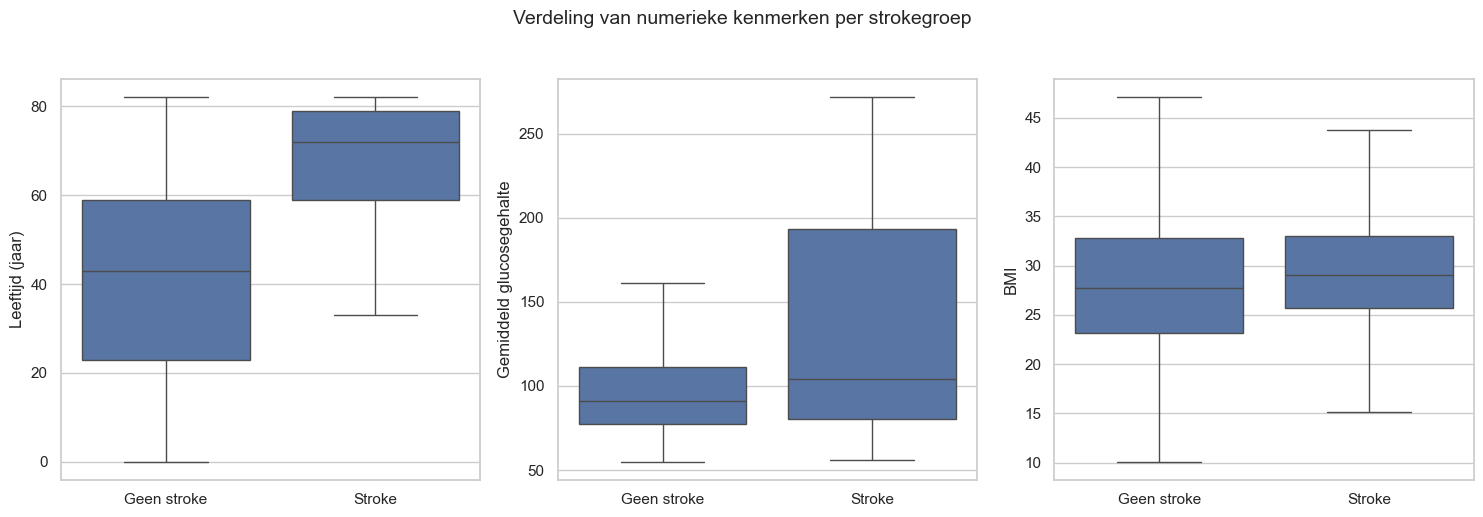

In [ ]:

if "stroke" not in df.columns:
    raise KeyError("Kolom 'stroke' ontbreekt in df.")

sns.set_theme(style="whitegrid", palette="deep")


numeriek = ["age", "avg_glucose_level", "bmi"]
labels = {
    "age": "Leeftijd (jaar)",
    "avg_glucose_level": "Gemiddeld glucosegehalte",
    "bmi": "BMI",
}
beschikbaar_numeriek = [kolom for kolom in numeriek if kolom in df.columns]

if beschikbaar_numeriek:
    fig, axes = plt.subplots(1, len(beschikbaar_numeriek), figsize=(5 * len(beschikbaar_numeriek), 5))
    if len(beschikbaar_numeriek) == 1:
        axes = [axes]

    for ax, kolom in zip(axes, beschikbaar_numeriek):
        sns.boxplot(data=df, x="stroke", y=kolom, ax=ax, showfliers=False)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Geen stroke", "Stroke"])
        ax.set_xlabel("")
        ax.set_ylabel(labels[kolom])

    fig.suptitle("Verdeling van numerieke kenmerken per strokegroep", y=1.03, fontsize=14)
    plt.tight_layout()
    plt.show()

##### Waarom is gekozen voor boxplots?
Leeftijd, gemiddeld glucosegehalte en BMI zijn numerieke, continue kenmerken. Een boxplot is geschikt om zulke waarden tussen twee groepen te vergelijken: personen zonder stroke en personen met een stroke. In één compacte grafiek toont een boxplot zowel het centrale niveau als de spreiding van de waarden. Daardoor is niet alleen zichtbaar of één groep gemiddeld hoger of lager ligt, maar ook hoeveel de waarden binnen beide groepen overlappen.

##### Wat laat de boxplot zien?
De horizontale lijn in de box is de mediaan: de middelste waarneming wanneer alle waarden op volgorde staan. De onder- en bovenkant van de box zijn respectievelijk het eerste en derde kwartiel. De box bevat dus de middelste 50% van de personen. De lijnen buiten de box (de ‘snorren’) geven de gebruikelijke spreiding buiten dat middelste gebied weer. In deze code zijn uitschieters niet afzonderlijk getoond (showfliers=False). Dit houdt de figuur overzichtelijk, vooral wanneer een kenmerk zoals glucose enkele zeer hoge waarden bevat. De uitschieters blijven wel in de berekening van de boxplot; ze worden alleen niet als losse punten weergegeven.

##### Wat valt op en welke conclusie past daarbij?
Bij leeftijd ligt de box van de strokegroep duidelijk hoger dan die van de groep zonder stroke. Ook de mediaan ligt hoger. Dit wijst op een sterk beschrijvend verband: in deze dataset komen strokes vooral voor bij oudere personen. Leeftijd is daarom een belangrijk kenmerk om mee te nemen in verdere analyses.

Bij gemiddeld glucosegehalte ligt de verdeling van de strokegroep doorgaans hoger. Tegelijkertijd is de spreiding groot en overlappen de boxen deels. Een hoger glucosegehalte lijkt dus samen te hangen met een hoger strokepercentage, maar glucose alleen onderscheidt de groepen niet volledig.

Bij BMI overlappen de boxen meestal sterk. Als de medianen dicht bij elkaar liggen, is er op basis van deze figuur geen groot zelfstandig verschil tussen de twee groepen zichtbaar. Dat sluit een effect van BMI niet uit: een mogelijk verband kan kleiner zijn, beïnvloed worden door leeftijd of andere risicofactoren, of pas zichtbaar worden in een multivariaat model.

##### Waarom past deze visualisatie bij deze gegevens?
De uitkomstvariabele stroke bestaat uit twee groepen (0 en 1), terwijl de drie onderzochte kenmerken numeriek zijn. Boxplots zijn precies bedoeld voor deze combinatie: een numerieke verdeling per categorie vergelijken. Ze zijn bovendien robuuster dan alleen een gemiddelde, omdat de mediaan minder gevoelig is voor extreem hoge of lage waarden.

#### 4.2 Binaire medische kenmerken

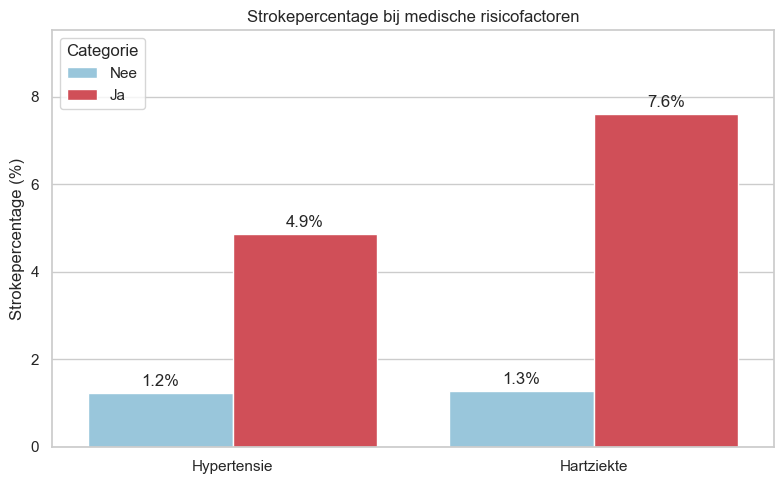

In [11]:

binair = ["hypertension", "heart_disease"]
mooie_binaire_namen = {
    "hypertension": "Hypertensie",
    "heart_disease": "Hartziekte",
}
rijen = []

for kolom in binair:
    if kolom not in df.columns:
        continue
    percentages = df.groupby(kolom)["stroke"].mean().mul(100)
    for waarde, percentage in percentages.items():
        rijen.append({
            "Kenmerk": mooie_binaire_namen[kolom],
            "Categorie": "Ja" if waarde == 1 else "Nee",
            "Strokepercentage": percentage,
        })

plotdata_binair = pd.DataFrame(rijen)
if not plotdata_binair.empty:
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(
        data=plotdata_binair,
        x="Kenmerk",
        y="Strokepercentage",
        hue="Categorie",
        hue_order=["Nee", "Ja"],
        palette=["#8ecae6","#e63946"],
    )
    ax.set(
        title="Strokepercentage bij medische risicofactoren",
        xlabel="",
        ylabel="Strokepercentage (%)",
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)
    plt.ylim(0, plotdata_binair["Strokepercentage"].max() * 1.25)
    plt.tight_layout()
    plt.show()


##### Waarom is gekozen voor een gegroepeerde balkgrafiek?
hypertension en heart_disease zijn binaire kenmerken: iemand heeft de aandoening wel (Ja) of niet (Nee). Voor dergelijke categorieën is het logisch om per categorie het strokepercentage te berekenen en als balk weer te geven. Een gegroepeerde balkgrafiek maakt het verschil tussen Ja en Nee binnen elk medisch kenmerk direct afleesbaar.

##### Wat laat de visualisatie zien?
Elke balk geeft het aandeel personen met een stroke binnen die specifieke groep weer. De percentages worden berekend als het gemiddelde van de binaire kolom stroke binnen elke categorie, vermenigvuldigd met 100. Een rode balk bij bijvoorbeeld Hartziekte – Ja toont dus: van alle personen met hartziekte, welk percentage heeft een stroke gehad? De labels op de balken maken de precieze percentages zichtbaar, zodat de lezer niet alleen visueel maar ook numeriek kan vergelijken.

##### Wat valt op en welke conclusie past daarbij?
De balken voor Ja zijn bij hypertensie en hartziekte hoger dan die voor Nee. Personen met deze medische risicofactoren hebben in deze dataset dus relatief vaker een stroke. Als het verschil bij hartziekte het grootst is, is hartziekte in de beschrijvende analyse de sterkste van deze twee signalen.

De juiste conclusie is dat beide kenmerken samenhangen met een hoger strokepercentage. De grafiek bewijst niet dat hypertensie of hartziekte op zichzelf de oorzaak is van de stroke. Personen met deze aandoeningen zijn bijvoorbeeld mogelijk ook gemiddeld ouder. Bovendien zegt de grafiek niets over de onzekerheid rond de percentages of over de omvang van de groepen. Rapporteer daarom bij een definitieve analyse ook de groepsgroottes en toets de verbanden in een multivariaat model.

##### Waarom past deze visualisatie bij deze gegevens?
De variabelen bestaan uit slechts twee duidelijke categorieën en de uitkomst is eveneens binair. Percentages per groep zijn daardoor goed interpreteerbaar. Een balkgrafiek communiceert dit sneller dan een tabel, terwijl de absolute schaal op de y-as eerlijke vergelijking van de verschillen mogelijk maakt.

#### 4.3 Categorische kenmerken

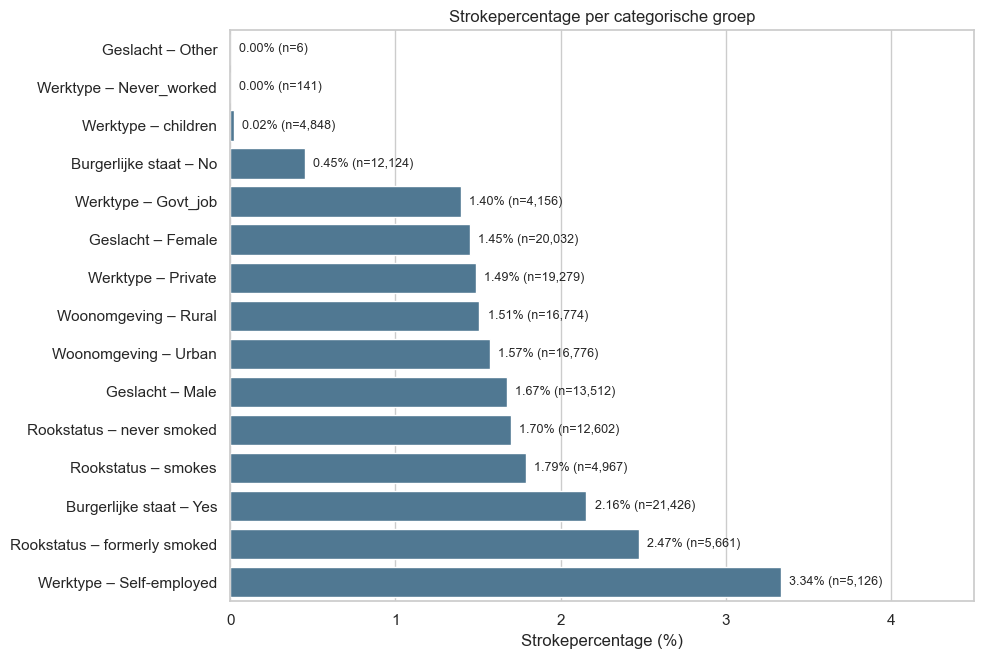

In [ ]:
categorisch = {
    "gender": "Geslacht",
    "ever_married": "Burgerlijke staat",
    "work_type": "Werktype",
    "Residence_type": "Woonomgeving",
    "smoking_status": "Rookstatus",
}
rijen = []

# Ondersteunt zowel originele categorische kolommen als dummy-/one-hotkolommen.
for basis_kolom, mooie_naam in categorisch.items():
    if basis_kolom in df.columns:
        samenvatting = df.groupby(basis_kolom, dropna=False)["stroke"].agg(["count", "mean"]).reset_index()
        for _, rij in samenvatting.iterrows():
            categorie = "Onbekend" if pd.isna(rij[basis_kolom]) else str(rij[basis_kolom])
            rijen.append({
                "Kenmerk": mooie_naam,
                "Categorie": categorie,
                "Aantal": int(rij["count"]),
                "Strokepercentage": rij["mean"] * 100,
            })
    else:
        dummy_kolommen = [kolom for kolom in df.columns if kolom.startswith(f"{basis_kolom}_")]
        for dummy in dummy_kolommen:
            categorie = dummy[len(basis_kolom) + 1:]
            subset = df.loc[df[dummy] == 1, "stroke"]
            if not subset.empty:
                rijen.append({
                    "Kenmerk": mooie_naam,
                    "Categorie": categorie,
                    "Aantal": int(subset.count()),
                    "Strokepercentage": subset.mean() * 100,
                })

plotdata_cat = pd.DataFrame(rijen)
if not plotdata_cat.empty:
    plotdata_cat["Label"] = plotdata_cat["Kenmerk"] + " – " + plotdata_cat["Categorie"]
    plotdata_cat = plotdata_cat.sort_values("Strokepercentage")

    plt.figure(figsize=(10, max(6, len(plotdata_cat) * 0.45)))
    ax = sns.barplot(data=plotdata_cat, x="Strokepercentage", y="Label", color="#457b9d")
    ax.set(
        title="Strokepercentage per categorische groep",
        xlabel="Strokepercentage (%)",
        ylabel="",
    )

    for i, (_, rij) in enumerate(plotdata_cat.iterrows()):
        ax.text(
            rij["Strokepercentage"] + 0.05,
            i,
            f'{rij["Strokepercentage"]:.2f}% (n={rij["Aantal"]:,})',
            va="center",
            fontsize=9,
        )

    plt.xlim(0, plotdata_cat["Strokepercentage"].max() * 1.35)
    plt.tight_layout()
    plt.show()


##### Waarom is gekozen voor een horizontale balkgrafiek?
De kenmerken geslacht, burgerlijke staat, werktype, woonomgeving en rookstatus bestaan uit meerdere categorieën. Een horizontale balkgrafiek is hiervoor geschikt, omdat categorienamen zoals formerly smoked of Self-employed relatief lang kunnen zijn. Horizontale labels blijven leesbaar en alle groepen kunnen in één overzicht worden vergeleken. Door de balken te sorteren van laag naar hoog ontstaat bovendien direct een rangorde in strokepercentage.

##### Wat laat de visualisatie zien?
Elke balk is één categorie binnen één kenmerk. De lengte van de balk is het percentage strokes binnen die categorie. Het label aan het einde van de balk bevat daarnaast het percentage én de groepsgrootte (n). Daardoor is niet alleen te zien welke categorieën hoog of laag scoren, maar ook hoeveel waarnemingen achter dat percentage zitten.

Bijvoorbeeld: een hoog percentage bij work_type_Self-employed betekent dat binnen de groep zelfstandigen een relatief groot deel een stroke heeft. Een zeer laag percentage bij children betekent dat in de groep kinderen vrijwel geen strokes voorkomen. Dit is inhoudelijk plausibel, maar hangt zeer waarschijnlijk sterk samen met leeftijd: kinderen zijn veel jonger dan de overige groepen.

##### Wat valt op en welke conclusie past daarbij?
Categorieën zoals zelfstandigen en voormalige rokers kunnen relatief hoge strokepercentages laten zien. Groepen zoals children, Unknown en ever_married_No hebben vaak lage percentages. Deze verschillen mogen niet geïsoleerd worden geïnterpreteerd. Ze kunnen grotendeels het gevolg zijn van verschillen in leeftijd, gezondheid of andere kenmerken tussen de groepen. Zo zijn voormalige rokers vaak ouder dan nooit-rokers, en personen die nooit getrouwd zijn of kinderen zijn gemiddeld vaak jonger.

Ook de groepsgrootte is essentieel. Een hoog of laag percentage in een kleine categorie is instabieler dan hetzelfde percentage in een grote categorie. Daarom zijn gender_Other (n = 6) en work_type_Never_worked (n = 141) te klein voor betrouwbare, zelfstandige conclusies. Eén of enkele extra strokegevallen kunnen het percentage in zo’n kleine groep sterk veranderen.

##### Waarom past deze visualisatie bij deze gegevens?
De verklarende variabelen zijn nominaal: de categorieën hebben geen natuurlijke numerieke schaal. Het gemiddelde van stroke binnen iedere categorie is wel betekenisvol, omdat stroke 0 of 1 is; dit gemiddelde is precies het strokepercentage. De balkgrafiek zet die percentages overzichtelijk naast elkaar en is daardoor geschikt voor een eerste, beschrijvende verkenning.


### 5. Belangrijkste bevindingen




1. De data is schoon: geen missende waarden, dubbele rijen of dubbele identifiers. Na het verwijderen van `id` is de data technisch geschikt voor Scikit-Learn.
2. De target is **extreem ongebalanceerd**: slechts 1,54% van de patiënten heeft een stroke. Gebruik daarom een gestratificeerde validatiestrategie, F1-score en technieken zoals klasseweging of resampling binnen trainingsfolds.
3. **Leeftijd** is het duidelijkste individuele signaal. De groep met stroke is gemiddeld aanzienlijk ouder.
4. **Hartziekte** en **hypertensie** hebben sterke bivariate associaties met stroke; het strokepercentage is respectievelijk 7,62% en 4,87% in de positieve groepen.
5. Een hoger **gemiddeld glucosegehalte** komt vaker voor bij stroke. **BMI** laat daarentegen slechts een zwak verschil zien.
6. Rookstatus, burgerlijke staat en werktype laten verschillen zien, maar deze hangen waarschijnlijk deels samen met leeftijd. Gebruik modellen met meerdere features en controleer prestaties via cross-validatie.
7. De hoge glucose- en BMI-waarden zijn volgens de IQR-regel potentiële uitschieters. Ze zijn medisch plausibel en moeten niet automatisch worden verwijderd. Controleer eventueel robuustheid met `RobustScaler` of vergelijk modellen met en zonder outlierbehandeling.
